# Mango Leaf Disease Classification (MangoLeafBD) - Part 3 (Custom CNN + MobileNetV2)

**Dataset:** MangoLeafBD, 4,000 images, 8 classes (7 diseases + healthy). Kaggle: `aryashah2k/mango-leaf-disease-dataset`.

**Models:** Custom CNN (trained from scratch) and MobileNetV2 (ImageNet transfer learning).

**Pipeline (7 steps):** setup → load & analyse → remove duplicates → split, preprocess & before/after graphs → train 2 models → evaluate (per-model graphs) → compare (line + bar graphs) & final result.

**Notes**
- Turn **Internet ON** so ImageNet weights can download (falls back to random init if not).
- Use a **GPU** accelerator (T4 / P100).
- About 1,800 distinct leaves; the rest are zoomed/rotated copies. Near-duplicates are grouped so they never straddle train/val/test.

## Step 1. Setup and configuration

In [1]:
import os, hashlib, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import MaxNLocator
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121, InceptionV3, ResNet50, EfficientNetB0, MobileNetV2
from tensorflow.keras.applications import densenet, inception_v3, resnet50, efficientnet, mobilenet_v2
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

warnings.filterwarnings("ignore"); sns.set_style("whitegrid")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

# ---- configuration ----
DATA_ROOT    = "/kaggle/input/mango-leaf-disease-dataset"   # change if your input folder is named differently
IMG_SIZE     = 224
BATCH_SIZE   = 32
EPOCHS_HEAD  = 8      # phase 1: train head (backbone frozen)
EPOCHS_FT    = 8      # phase 2: fine-tune top of backbone
TARGET_ACC   = 0.85
NEAR_DUP_THR = 4      # max Hamming distance (64-bit dHash) to treat images as near-duplicates
MODEL_NAMES  = ["CustomCNN", "MobileNetV2"]
MODEL_COLORS = {"CustomCNN": "#34495e", "MobileNetV2": "#d35400", "DenseNet121": "#7b5ea7", "InceptionV3": "#e08a1e", "ResNet50": "#2a9d8f", "EfficientNetB0": "#c0392b"}
INPUT_SHAPE  = (IMG_SIZE, IMG_SIZE, 3)
OUT_DIR      = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
FIG_DIR      = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

# augmentation: training only (inactive at val/test time)
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.15),
], name="augmentation")

print("TensorFlow:", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.20.0 | GPUs: 2


I0000 00:00:1792989307.136573      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792989307.140529      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Step 2. Load, analyse and check image sizes

Total images: 4000 | classes: 8
label
Anthracnose         500
Bacterial Canker    500
Cutting Weevil      500
Die Back            500
Gall Midge          500
Healthy             500
Powdery Mildew      500
Sooty Mould         500
Imbalance ratio (max/min): 1.00 -> balanced


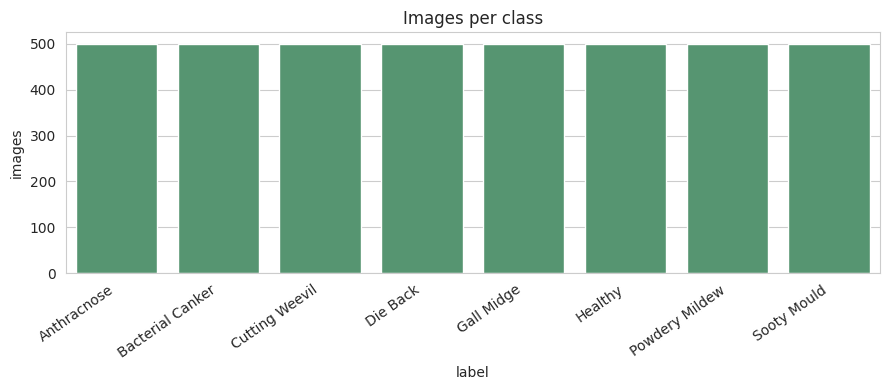

         width   height   aspect
count  4000.00  4000.00  4000.00
mean    274.92   260.27     1.09
std      39.74    35.98     0.26
min     187.00    70.00     0.58
25%     240.00   240.00     0.75
50%     240.00   240.00     1.00
75%     320.00   320.00     1.33
max     320.00   320.00     4.57

Most common sizes (W x H):
width  height
320    240       1668
240    240       1187
       320       1018
320    220          5
       226          4
All images share one size: False -> all resized to (224, 224)


In [2]:
EXTS = (".jpg", ".jpeg", ".png", ".bmp")
root = DATA_ROOT if os.path.exists(DATA_ROOT) else "/kaggle/input"
rows = []
for dirpath, _, files in os.walk(root):
    for f in files:
        if f.lower().endswith(EXTS):
            rows.append((os.path.join(dirpath, f), os.path.basename(dirpath)))
df = pd.DataFrame(rows, columns=["path", "label"]).sort_values("path").reset_index(drop=True)
assert len(df) > 0, "No images found. Check DATA_ROOT / that the dataset is attached."

# class balance
raw_counts = df.label.value_counts().sort_index()
imbalance = raw_counts.max() / raw_counts.min()
print(f"Total images: {len(df)} | classes: {len(raw_counts)}")
print(raw_counts.to_string())
print(f"Imbalance ratio (max/min): {imbalance:.2f} ->", "balanced" if imbalance < 1.5 else "imbalanced (consider class weights)")
plt.figure(figsize=(9, 4))
sns.barplot(x=raw_counts.index, y=raw_counts.values, color="#4c9f70")
plt.xticks(rotation=35, ha="right"); plt.ylabel("images"); plt.title("Images per class")
plt.tight_layout(); plt.show()

# image sizes
sizes = [Image.open(p).size for p in df.path]
df["width"]  = [s[0] for s in sizes]
df["height"] = [s[1] for s in sizes]
df["aspect"] = df.width / df.height
print(df[["width", "height", "aspect"]].describe().round(2).to_string())
print("\nMost common sizes (W x H):")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(5).to_string())
print("All images share one size:", df[["width", "height"]].drop_duplicates().shape[0] == 1,
      "-> all resized to", (IMG_SIZE, IMG_SIZE))

raw_df = df.copy()          # kept for the BEFORE graphs (includes duplicates)
N_RAW = len(raw_df)

## Step 3. Remove exact duplicates and group near-duplicates

In [4]:
def md5_file(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def dhash(p, size=8):
    img = Image.open(p).convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(img, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten().astype(np.uint8)

md5s, hashes, bad = [], [], []
for p in df.path:
    try:
        md5s.append(md5_file(p)); hashes.append(dhash(p))
    except Exception:
        md5s.append(None); hashes.append(np.zeros(64, np.uint8)); bad.append(p)
print("Unreadable / corrupt images:", len(bad))

ok = np.array([m is not None for m in md5s])
df = df[ok].reset_index(drop=True)
df["md5"] = [m for m in md5s if m is not None]
H = np.stack([h for h, o in zip(hashes, ok) if o])

# exact duplicates (identical bytes) -> removed
dup = df.duplicated("md5", keep="first").values
print("Exact duplicates removed:", dup.sum())
df, H = df[~dup].reset_index(drop=True), H[~dup]
N_AFTER_DEDUP = len(df)

# near duplicates (dHash Hamming distance <= threshold) -> kept, grouped with union-find
N = len(df); Hf = H.astype(np.float32)
dist = Hf @ (1 - Hf).T + (1 - Hf) @ Hf.T
ii, jj = np.where(np.triu(dist <= NEAR_DUP_THR, k=1))
del dist

parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in zip(ii, jj):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
df["group"] = [find(i) for i in range(N)]

grp_sizes = df.groupby("group").size()
conflict = df.groupby("group").label.nunique()
print(f"Images after de-dup             : {N_AFTER_DEDUP}")
print(f"Near-duplicate pairs            : {len(ii)}")
print(f"Groups with more than 1 image   : {(grp_sizes > 1).sum()}  ({grp_sizes[grp_sizes > 1].sum()} images)")
print(f"Groups with conflicting labels  : {(conflict > 1).sum()}  (label-noise red flag)")

Unreadable / corrupt images: 0
Exact duplicates removed: 21
Images after de-dup             : 3979
Near-duplicate pairs            : 839
Groups with more than 1 image   : 332  (930 images)
Groups with conflicting labels  : 24  (label-noise red flag)


## Step 4. Split, preprocess and before/after graphs

Group-aware 70 / 15 / 15 split (near-duplicates stay together), then a `tf.data` pipeline: decode → resize to 224×224 → batch → prefetch. Backbone-specific scaling (`preprocess_input`) is applied inside each model.

train=2839  val=566  test=574
                  train  val  test
label                             
Anthracnose         323   80    83
Bacterial Canker    354   75    71
Cutting Weevil      336   68    96
Die Back            394   47    52
Gall Midge          366   56    78
Healthy             356   78    66
Powdery Mildew      364   79    57
Sooty Mould         346   83    71


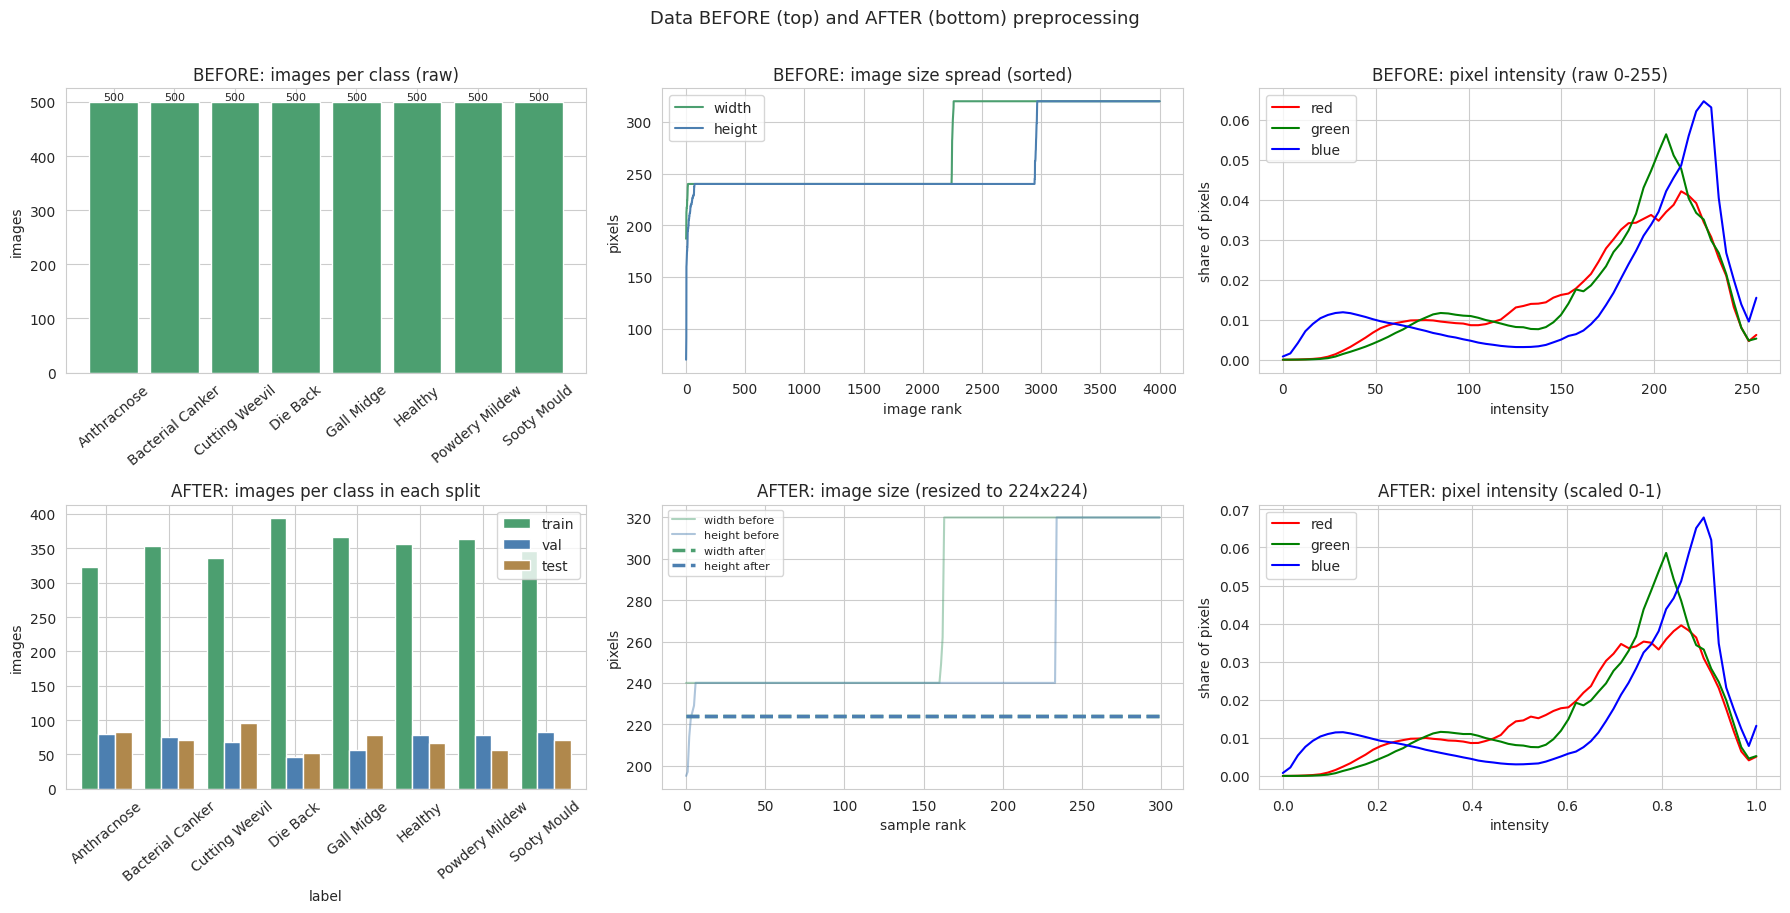

In [5]:
class_names = sorted(df.label.unique())
label2id = {c: i for i, c in enumerate(class_names)}
df["y"] = df.label.map(label2id)
NUM_CLASSES = len(class_names)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_idx, tmp_idx = next(gss1.split(df, df.y, groups=df.group))
tmp = df.iloc[tmp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
va_rel, te_rel = next(gss2.split(tmp, tmp.y, groups=tmp.group))
train_df, val_df, test_df = df.iloc[tr_idx], tmp.iloc[va_rel], tmp.iloc[te_rel]

split_counts = pd.DataFrame({"train": train_df.label.value_counts(),
                             "val":   val_df.label.value_counts(),
                             "test":  test_df.label.value_counts()}).fillna(0).astype(int).sort_index()
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
print(split_counts.to_string())

def _load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE)), y

def make_ds(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.y.values.astype("int32")))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

# ---- before / after graphs (300-image sample) ----
def channel_hist(imgs, vmax, bins=64):
    h = np.zeros((3, bins))
    for a in imgs:
        for c in range(3):
            h[c] += np.histogram(a[..., c], bins=bins, range=(0, vmax))[0]
    return h / h.sum(axis=1, keepdims=True)

sample_raw = raw_df.sample(min(300, len(raw_df)), random_state=SEED)
raw_hist = channel_hist((np.asarray(Image.open(p).convert("RGB"), dtype=np.float32) for p in sample_raw.path), 255)
proc_imgs = [_load(tf.constant(p), 0)[0].numpy() / 255.0 for p in sample_raw.path]   # scaled 0-1 for graphs only
proc_hist = channel_hist(proc_imgs, 1.0)
proc_shapes = np.array([a.shape[:2] for a in proc_imgs])

fig, ax = plt.subplots(2, 3, figsize=(18, 9))

# row 1: BEFORE
b = ax[0, 0].bar(raw_counts.index, raw_counts.values, color="#4c9f70"); ax[0, 0].bar_label(b, fontsize=8)
ax[0, 0].set_title("BEFORE: images per class (raw)"); ax[0, 0].set_ylabel("images"); ax[0, 0].tick_params(axis="x", rotation=40)
ax[0, 1].plot(np.sort(raw_df.width.values),  color="#4c9f70", label="width")
ax[0, 1].plot(np.sort(raw_df.height.values), color="#4c7fb0", label="height")
ax[0, 1].set_title("BEFORE: image size spread (sorted)"); ax[0, 1].set_xlabel("image rank"); ax[0, 1].set_ylabel("pixels"); ax[0, 1].legend()
xs = np.linspace(0, 255, raw_hist.shape[1])
for c, col in enumerate(("red", "green", "blue")):
    ax[0, 2].plot(xs, raw_hist[c], color=col, label=col)
ax[0, 2].set_title("BEFORE: pixel intensity (raw 0-255)"); ax[0, 2].set_xlabel("intensity"); ax[0, 2].set_ylabel("share of pixels"); ax[0, 2].legend()

# row 2: AFTER
split_counts.plot(kind="bar", ax=ax[1, 0], width=0.8, color=["#4c9f70", "#4c7fb0", "#b0884c"])
ax[1, 0].set_title("AFTER: images per class in each split"); ax[1, 0].set_ylabel("images"); ax[1, 0].tick_params(axis="x", rotation=40)
ax[1, 1].plot(np.sort(sample_raw.width.values),  color="#4c9f70", alpha=0.45, label="width before")
ax[1, 1].plot(np.sort(sample_raw.height.values), color="#4c7fb0", alpha=0.45, label="height before")
ax[1, 1].plot(np.sort(proc_shapes[:, 1]), color="#4c9f70", lw=2.5, ls="--", label="width after")
ax[1, 1].plot(np.sort(proc_shapes[:, 0]), color="#4c7fb0", lw=2.5, ls="--", label="height after")
ax[1, 1].set_title("AFTER: image size (resized to 224x224)"); ax[1, 1].set_xlabel("sample rank"); ax[1, 1].set_ylabel("pixels"); ax[1, 1].legend(fontsize=8)
xs1 = np.linspace(0, 1, proc_hist.shape[1])
for c, col in enumerate(("red", "green", "blue")):
    ax[1, 2].plot(xs1, proc_hist[c], color=col, label=col)
ax[1, 2].set_title("AFTER: pixel intensity (scaled 0-1)"); ax[1, 2].set_xlabel("intensity"); ax[1, 2].set_ylabel("share of pixels"); ax[1, 2].legend()

fig.suptitle("Data BEFORE (top) and AFTER (bottom) preprocessing", fontsize=13, y=1.01)
savefig("01_before_after_preprocessing"); plt.show()

## Step 5. Train both models (transfer learning, 2 phases each)

In [6]:
def build_custom_cnn(name="CustomCNN"):
    # small CNN trained from scratch (no ImageNet weights)
    inp = keras.Input(INPUT_SHAPE)
    x = augment(inp)
    x = layers.Rescaling(1.0 / 255, name="preprocess")(x)
    for filters in (32, 64, 128, 256):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name=name), None

def build_transfer(name):
    cfg = {"DenseNet121":    (DenseNet121,    densenet.preprocess_input),
           "InceptionV3":    (InceptionV3,    inception_v3.preprocess_input),
           "ResNet50":       (ResNet50,       resnet50.preprocess_input),
           "EfficientNetB0": (EfficientNetB0, efficientnet.preprocess_input),
           "MobileNetV2":    (MobileNetV2,    mobilenet_v2.preprocess_input)}[name]
    try:
        base = cfg[0](include_top=False, weights="imagenet", input_shape=INPUT_SHAPE); pretrained = True
    except Exception as e:
        print(f"[{name}] could not load ImageNet weights ({type(e).__name__}); using random init. Enable Internet.")
        base = cfg[0](include_top=False, weights=None, input_shape=INPUT_SHAPE); pretrained = False
    base.trainable = not pretrained
    inp = keras.Input(INPUT_SHAPE)
    x = augment(inp)
    x = layers.Lambda(cfg[1], name="preprocess")(x)
    x = base(x, training=False if pretrained else None)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name=name), base

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=0)]

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

def train_model(name):
    keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    t0 = time.time()
    if name == "CustomCNN":
        # from scratch: one phase, all layers trainable
        model, _ = build_custom_cnn(name)
        compile_model(model, 1e-3)
        h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD + EPOCHS_FT,
                      callbacks=callbacks(), verbose=2)
        return model, dict(h.history), time.time() - t0
    model, base = build_transfer(name)
    # phase 1: train head, backbone frozen
    compile_model(model, 1e-3)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks(), verbose=2)
    # phase 2: fine-tune top 30 backbone layers, BatchNorm kept frozen, low LR
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model, 1e-5)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=callbacks(), verbose=2)
    hist = merge_hist(h1, h2)
    hist["ft_start"] = len(h1.history["loss"])
    return model, hist, time.time() - t0

trained, histories, train_time = {}, {}, {}
for name in MODEL_NAMES:
    print("=" * 70, f"\nTraining {name}\n", "=" * 70, sep="")
    trained[name], histories[name], train_time[name] = train_model(name)
    print(f"{name} finished in {train_time[name] / 60:.1f} min")

Training CustomCNN
Epoch 1/16
89/89 - 48s - 538ms/step - accuracy: 0.7880 - loss: 0.6506 - val_accuracy: 0.0830 - val_loss: 4.1075 - learning_rate: 0.0010
Epoch 2/16
89/89 - 26s - 297ms/step - accuracy: 0.8538 - loss: 0.4326 - val_accuracy: 0.0830 - val_loss: 7.3999 - learning_rate: 0.0010
Epoch 3/16
89/89 - 27s - 300ms/step - accuracy: 0.8718 - loss: 0.3719 - val_accuracy: 0.2049 - val_loss: 6.7040 - learning_rate: 0.0010
Epoch 4/16
89/89 - 27s - 306ms/step - accuracy: 0.9324 - loss: 0.2317 - val_accuracy: 0.2067 - val_loss: 5.4561 - learning_rate: 3.0000e-04
Epoch 5/16
89/89 - 27s - 304ms/step - accuracy: 0.9405 - loss: 0.1902 - val_accuracy: 0.2968 - val_loss: 2.7862 - learning_rate: 3.0000e-04
Epoch 6/16
89/89 - 27s - 302ms/step - accuracy: 0.9366 - loss: 0.1977 - val_accuracy: 0.6237 - val_loss: 1.2435 - learning_rate: 3.0000e-04
Epoch 7/16
89/89 - 27s - 301ms/step - accuracy: 0.9412 - loss: 0.1816 - val_accuracy: 0.7014 - val_loss: 0.9026 - learning_rate: 3.0000e-04
Epoch 8/16
89

## Step 6. Evaluation on the held-out test set (graphs per model)

,Model,Val Acc,Test Acc,Test Macro-F1,Params (M),Train time (min)
1,CustomCNN,0.9770,0.9669,0.9654,1.18,7.6
2,MobileNetV2,0.1325,0.0906,0.0208,2.27,5.0


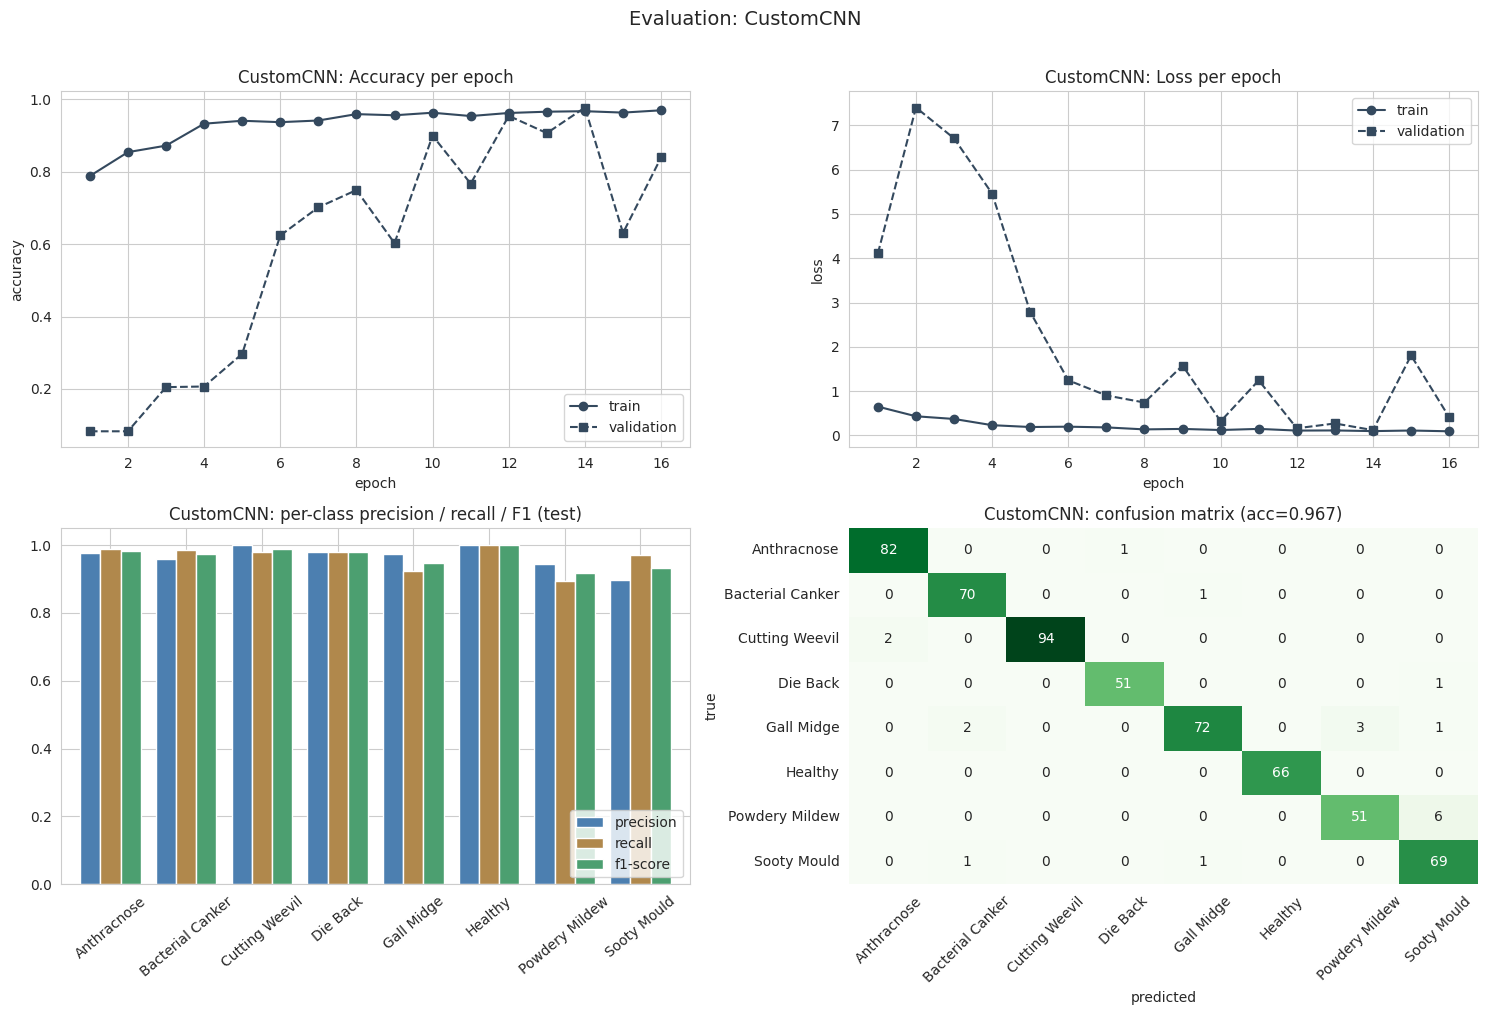

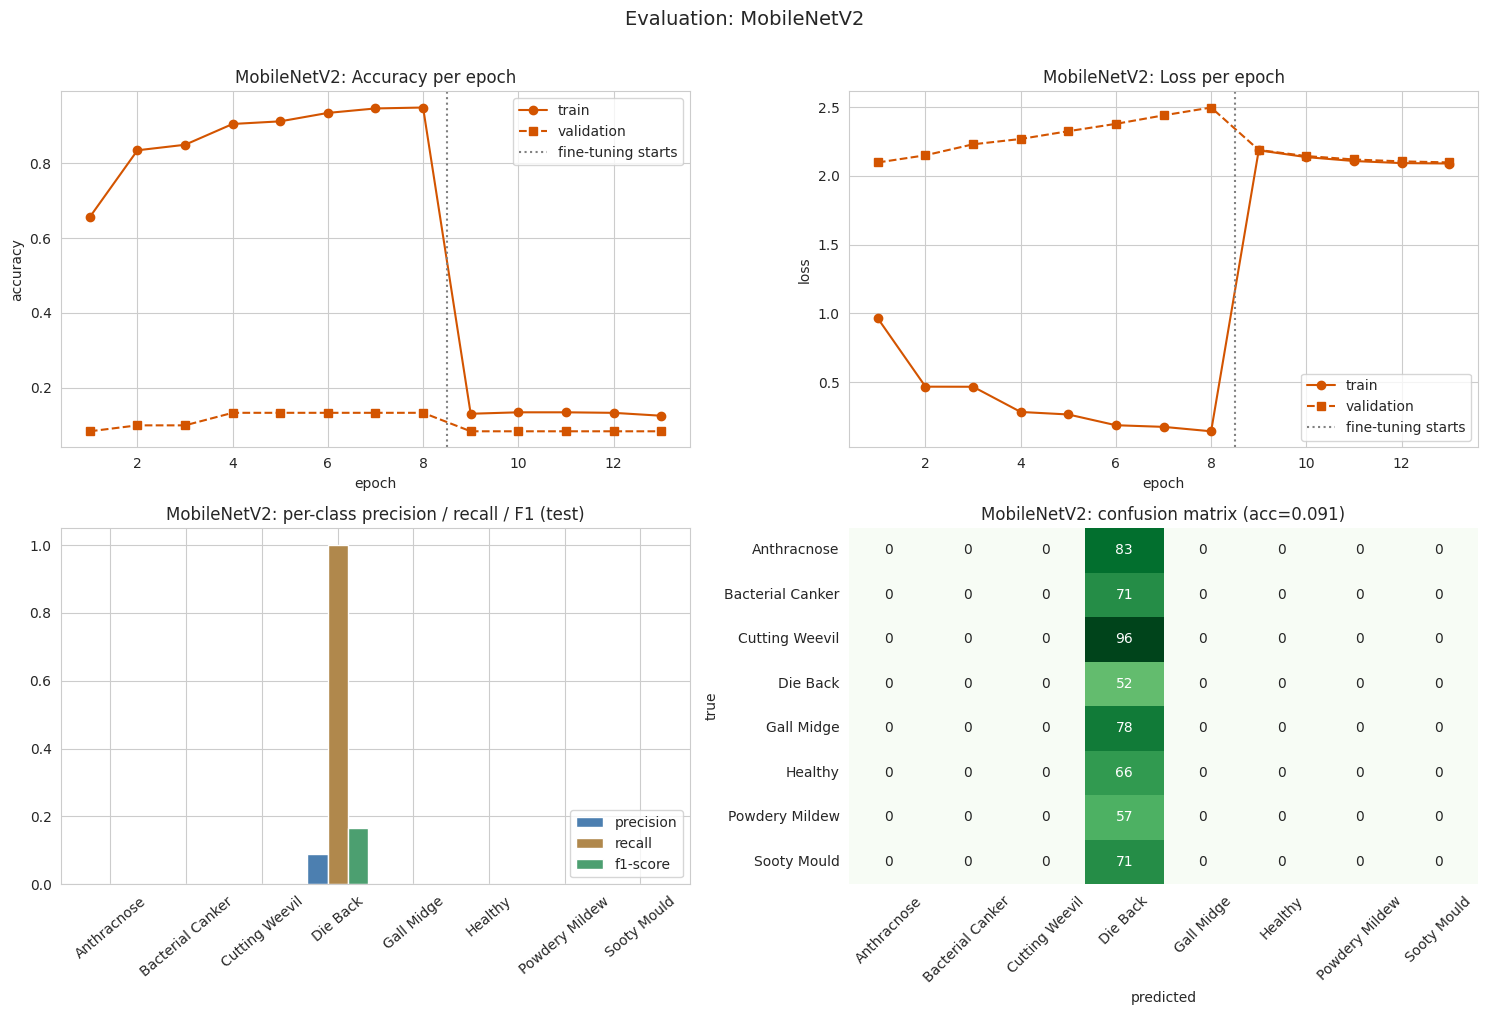

In [7]:
y_true = test_df.y.values
results, preds, reports = [], {}, {}
for name, model in trained.items():
    y_pred = model.predict(test_ds, verbose=0).argmax(1)
    preds[name] = y_pred
    h = histories[name]
    reports[name] = classification_report(y_true, y_pred, target_names=class_names, digits=3,
                                          output_dict=True, zero_division=0)
    results.append({
        "Model": name,
        "Val Acc": max(h["val_accuracy"]),
        "Test Acc": accuracy_score(y_true, y_pred),
        "Test Macro-F1": f1_score(y_true, y_pred, average="macro"),
        "Params (M)": model.count_params() / 1e6,
        "Train time (min)": train_time[name] / 60,
    })

res = pd.DataFrame(results).sort_values("Val Acc", ascending=False).reset_index(drop=True)
res.index += 1
display(res.style.format({"Val Acc": "{:.4f}", "Test Acc": "{:.4f}", "Test Macro-F1": "{:.4f}",
                          "Params (M)": "{:.2f}", "Train time (min)": "{:.1f}"})
        .background_gradient(subset=["Test Acc"], cmap="Greens"))

def plot_model_eval(name):
    h = histories[name]
    ep = np.arange(1, len(h["accuracy"]) + 1)
    col = MODEL_COLORS[name]
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))

    # line: accuracy and loss, train vs validation
    for a, (k, title) in zip(ax[0], (("accuracy", "Accuracy"), ("loss", "Loss"))):
        a.plot(ep, h[k], marker="o", color=col, label="train")
        a.plot(ep, h["val_" + k], marker="s", color=col, ls="--", label="validation")
        if h.get("ft_start"):
            a.axvline(h["ft_start"] + 0.5, color="grey", ls=":", label="fine-tuning starts")
        a.xaxis.set_major_locator(MaxNLocator(integer=True))
        a.set_title(f"{name}: {title} per epoch"); a.set_xlabel("epoch"); a.set_ylabel(k); a.legend()

    # bar: per-class precision / recall / F1
    rep = reports[name]
    prf = pd.DataFrame({m: [rep[c][m] for c in class_names] for m in ("precision", "recall", "f1-score")},
                       index=class_names)
    prf.plot(kind="bar", ax=ax[1, 0], width=0.8, color=["#4c7fb0", "#b0884c", "#4c9f70"])
    ax[1, 0].set_ylim(0, 1.05); ax[1, 0].set_title(f"{name}: per-class precision / recall / F1 (test)")
    ax[1, 0].tick_params(axis="x", rotation=40); ax[1, 0].legend(loc="lower right")

    # confusion matrix
    cm = confusion_matrix(y_true, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax[1, 1],
                xticklabels=class_names, yticklabels=class_names)
    ax[1, 1].set_title(f"{name}: confusion matrix (acc={accuracy_score(y_true, preds[name]):.3f})")
    ax[1, 1].set_xlabel("predicted"); ax[1, 1].set_ylabel("true"); ax[1, 1].tick_params(axis="x", rotation=45)

    fig.suptitle(f"Evaluation: {name}", fontsize=14, y=1.01)
    savefig(f"04_eval_{name}"); plt.show()

for name in MODEL_NAMES:
    plot_model_eval(name)

## Step 7. Model comparison, best model and final result

Best model is picked by **validation** accuracy (the test set is never used for selection) and must reach **> 85% test accuracy**.

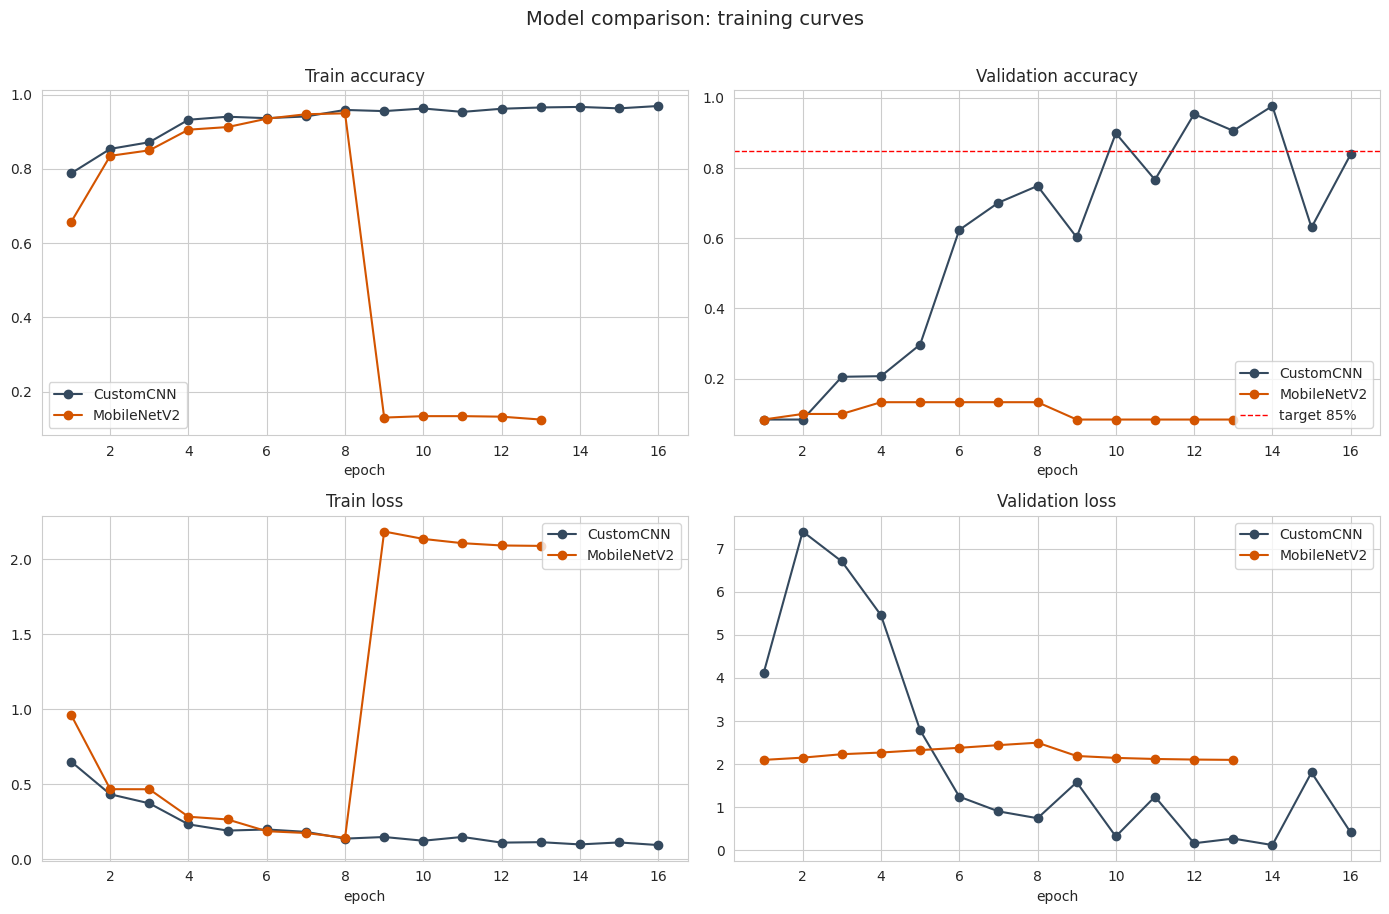

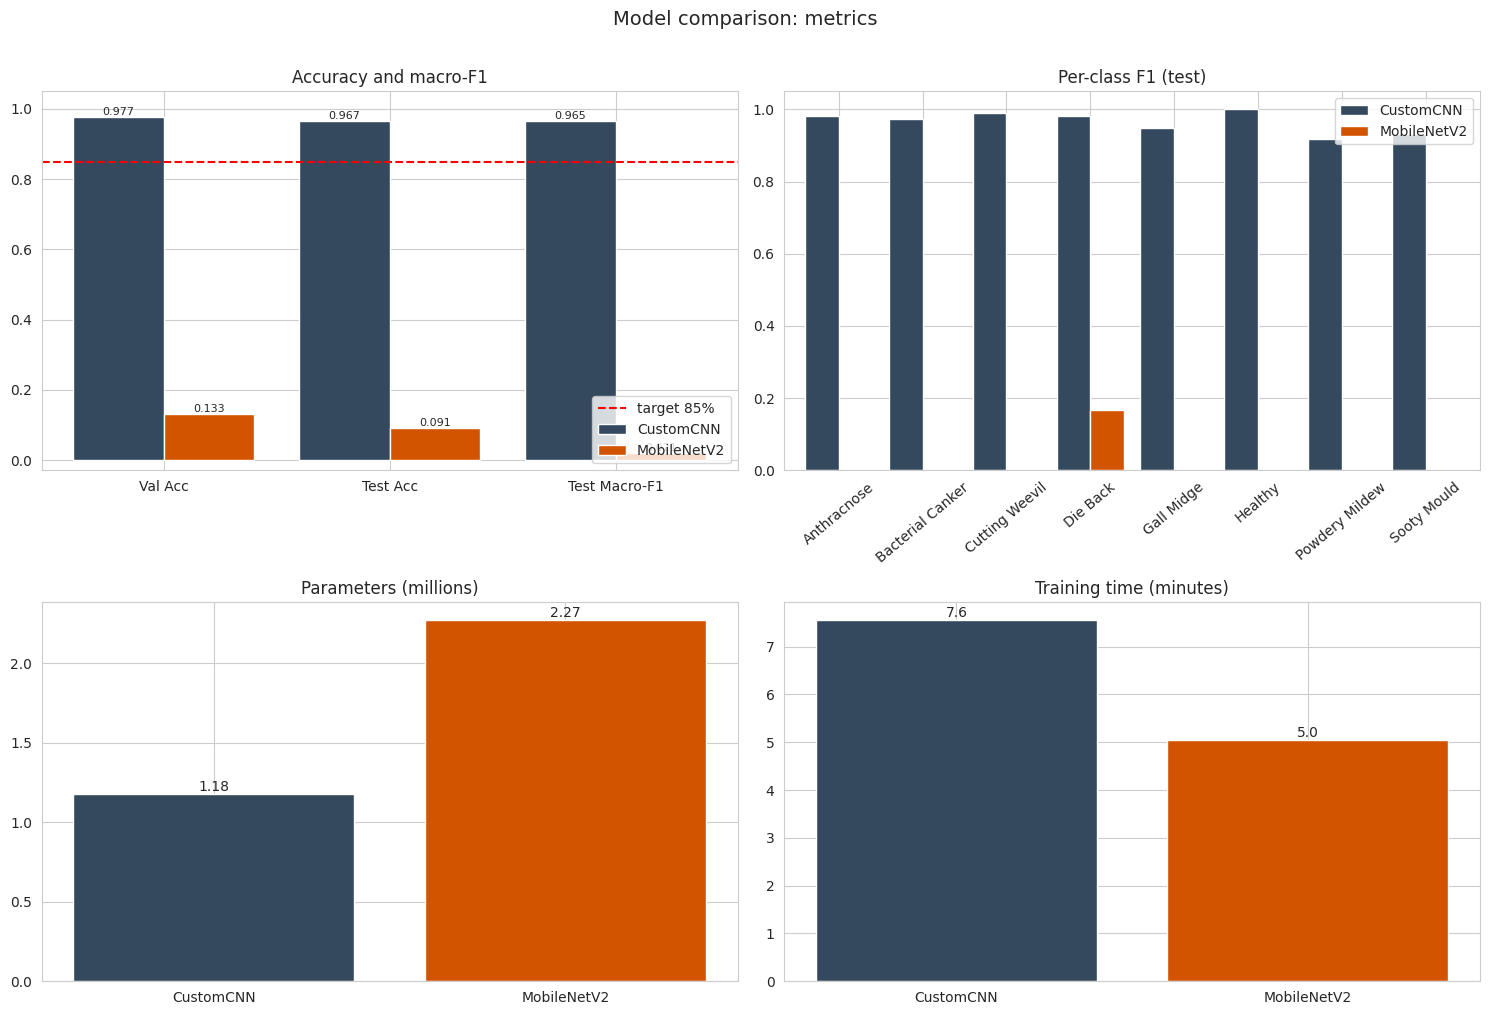

BEST MODEL      : CustomCNN
Validation acc  : 0.9770
Test accuracy   : 0.9669
Test macro-F1   : 0.9654
Models with test accuracy > 85%: CustomCNN
RESULT: PASS. CustomCNN exceeds the 85% accuracy target.

Per-class report for the best model:
                  precision    recall  f1-score   support

     Anthracnose      0.976     0.988     0.982        83
Bacterial Canker      0.959     0.986     0.972        71
  Cutting Weevil      1.000     0.979     0.989        96
        Die Back      0.981     0.981     0.981        52
      Gall Midge      0.973     0.923     0.947        78
         Healthy      1.000     1.000     1.000        66
  Powdery Mildew      0.944     0.895     0.919        57
     Sooty Mould      0.896     0.972     0.932        71

        accuracy                          0.967       574
       macro avg      0.966     0.965     0.965       574
    weighted avg      0.968     0.967     0.967       574

Saved best model.


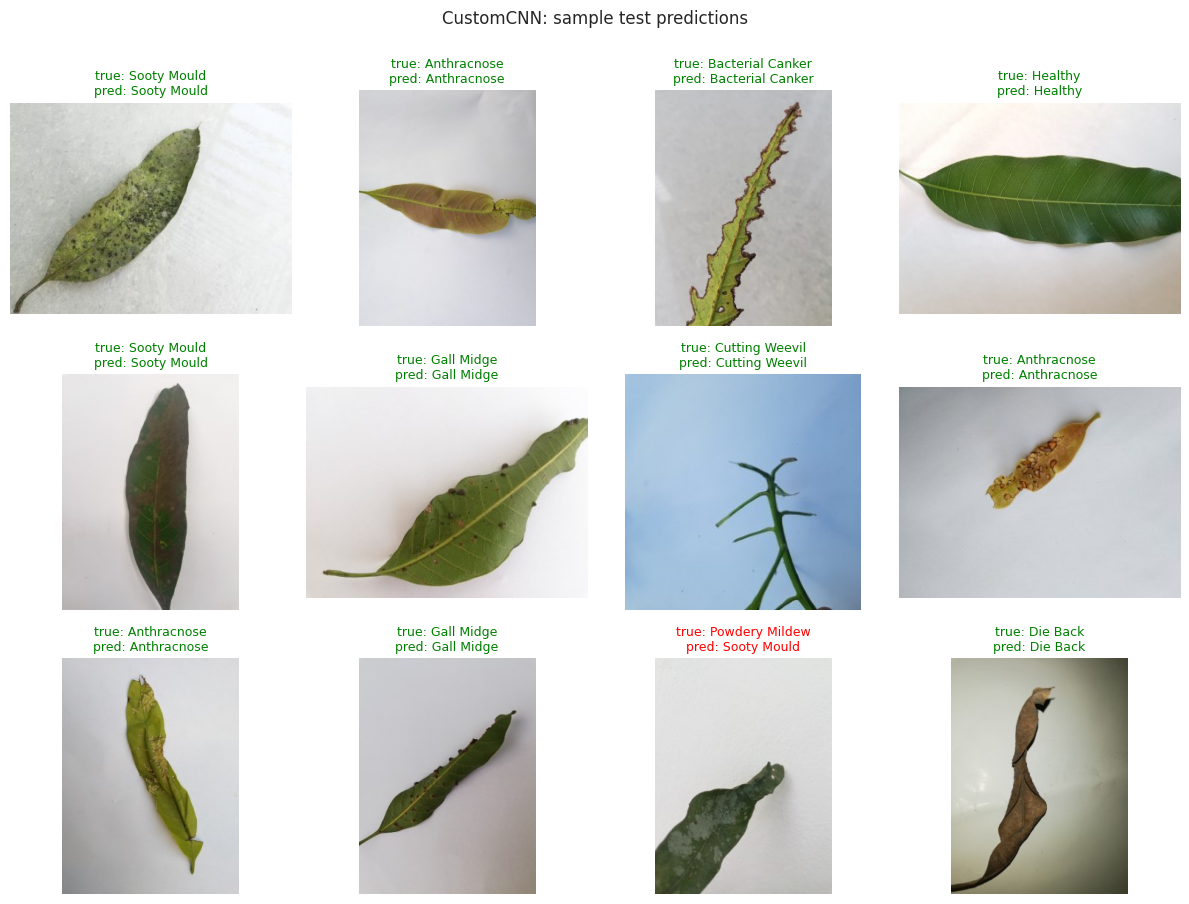

In [8]:
# ---- comparison: LINE graphs (training curves overlaid) ----
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
panels = (("accuracy", "Train accuracy", ax[0, 0]), ("val_accuracy", "Validation accuracy", ax[0, 1]),
          ("loss", "Train loss", ax[1, 0]), ("val_loss", "Validation loss", ax[1, 1]))
for key, title, a in panels:
    for name in MODEL_NAMES:
        h = histories[name]
        a.plot(np.arange(1, len(h[key]) + 1), h[key], marker="o", color=MODEL_COLORS[name], label=name)
    a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_title(title); a.set_xlabel("epoch"); a.legend()
ax[0, 1].axhline(TARGET_ACC, color="red", ls="--", lw=1, label=f"target {TARGET_ACC:.0%}"); ax[0, 1].legend()
fig.suptitle("Model comparison: training curves", fontsize=14, y=1.01)
savefig("05_comparison_lines"); plt.show()

# ---- comparison: BAR graphs ----
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
models = list(res["Model"]); n = len(models)

metrics = ["Val Acc", "Test Acc", "Test Macro-F1"]
x = np.arange(len(metrics)); w = 0.8 / n
for i, m in enumerate(models):
    vals = [res.loc[res.Model == m, k].values[0] for k in metrics]
    b = ax[0, 0].bar(x + (i - (n - 1) / 2) * w, vals, w, label=m, color=MODEL_COLORS[m])
    ax[0, 0].bar_label(b, fmt="%.3f", fontsize=8)
ax[0, 0].axhline(TARGET_ACC, color="red", ls="--", label=f"target {TARGET_ACC:.0%}")
ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(metrics)
ax[0, 0].set_ylim(min(0.5, res[metrics].min().min() - 0.05), 1.05)
ax[0, 0].set_title("Accuracy and macro-F1"); ax[0, 0].legend(loc="lower right")

f1 = pd.DataFrame({m: [reports[m][c]["f1-score"] for c in class_names] for m in models}, index=class_names)
f1.plot(kind="bar", ax=ax[0, 1], width=0.8, color=[MODEL_COLORS[m] for m in models])
ax[0, 1].set_ylim(0, 1.05); ax[0, 1].set_title("Per-class F1 (test)"); ax[0, 1].tick_params(axis="x", rotation=40)

b = ax[1, 0].bar(models, res["Params (M)"], color=[MODEL_COLORS[m] for m in models])
ax[1, 0].bar_label(b, fmt="%.2f"); ax[1, 0].set_title("Parameters (millions)")

b = ax[1, 1].bar(models, res["Train time (min)"], color=[MODEL_COLORS[m] for m in models])
ax[1, 1].bar_label(b, fmt="%.1f"); ax[1, 1].set_title("Training time (minutes)")

fig.suptitle("Model comparison: metrics", fontsize=14, y=1.01)
savefig("06_comparison_bars"); plt.show()

# ---- best model and final result ----
best_name = res.loc[1, "Model"]
best_row = res.loc[1]
best_model = trained[best_name]
best_pred = preds[best_name]

print("=" * 60)
print(f"BEST MODEL      : {best_name}")
print(f"Validation acc  : {best_row['Val Acc']:.4f}")
print(f"Test accuracy   : {best_row['Test Acc']:.4f}")
print(f"Test macro-F1   : {best_row['Test Macro-F1']:.4f}")
print("=" * 60)
passing = res[res["Test Acc"] > TARGET_ACC]
print(f"Models with test accuracy > {TARGET_ACC:.0%}: {', '.join(passing['Model']) if len(passing) else 'none'}")
if best_row["Test Acc"] > TARGET_ACC:
    print(f"RESULT: PASS. {best_name} exceeds the {TARGET_ACC:.0%} accuracy target.")
else:
    print(f"RESULT: FAIL. {best_name} is below the {TARGET_ACC:.0%} target; "
          "increase EPOCHS_*, unfreeze more layers, or try a larger input size.")
print("\nPer-class report for the best model:")
print(classification_report(y_true, best_pred, target_names=class_names, digits=3, zero_division=0))

# save artifacts
res.to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index_label="rank")
try:
    best_model.save(os.path.join(OUT_DIR, f"best_model_{best_name}.keras"))
    print("Saved best model.")
except Exception as e:
    best_model.save_weights(os.path.join(OUT_DIR, f"best_model_{best_name}.weights.h5"))
    print(f"Full-model save failed ({type(e).__name__}); saved weights instead.")

# sample predictions from the best model
idx = np.random.RandomState(SEED).choice(len(test_df), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for axis, i in zip(axes.flat, idx):
    row = test_df.iloc[i]
    axis.imshow(Image.open(row.path).convert("RGB")); axis.axis("off")
    ok_ = best_pred[i] == row.y
    axis.set_title(f"true: {class_names[row.y]}\npred: {class_names[best_pred[i]]}", fontsize=9,
                   color="green" if ok_ else "red")
plt.suptitle(f"{best_name}: sample test predictions", y=1.0)
plt.tight_layout(); plt.show()

## Final summary
- **Dataset:** MangoLeafBD, 4,000 images, 8 balanced classes.
- **Checks:** class balance, exact + near-duplicate detection, corrupt files, image sizes.
- **Leakage control:** near-duplicates grouped so they never straddle train/val/test.
- **Models:** Custom CNN (trained from scratch) and MobileNetV2 (ImageNet transfer learning).
- **Result:** printed in Step 7 (pass/fail against the 85% target).
- **Graphs:** before/after preprocessing (Step 4), per-model evaluation (Step 6), model comparison line + bar graphs (Step 7). PNGs are saved in `figures/`.